# 🇮🇳 India's National Air Intelligence Platform (NAIP)
## Centralized Cloud AI Hub — Real-Time CPCB API Edition

---

> **Role:** Senior AI Architect & Lead Data Scientist  
> **Version:** v2.1 Real-Time (data.gov.in API fix)  
> **Data Source:** CPCB Real-Time AQI via data.gov.in API  
> **Zones:** North (Delhi NCR) · West (Vadodara) · South (Bangalore) · East (Kolkata) · Central (Bhopal)  

---


## 🔑 How to Use
1. Set your `DATA_GOV_API_KEY` in **Cell 2** below (get it from [data.gov.in/user/api](https://data.gov.in/user/api)).
2. Run all cells top-to-bottom.
3. The system will fetch **live AQI data** from the official CPCB dataset on data.gov.in, train the model, and render the Policy Command Center.

---

> **Note:** The `data.gov.in` API returns the **latest snapshot** (current readings) for all ~550 stations across India.
> For each zone, the notebook fetches all stations in that state/city and builds a 72-hour dataset using the live readings
> combined with RIM-based temporal simulation, giving the model real current baselines.


In [1]:
import subprocess, sys

def install(pkg):
    subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])

for pkg in ["tf-nightly", "scikit-learn", "pandas", "numpy",
            "matplotlib", "seaborn", "requests", "pytz"]:
    install(pkg)

print("✅ All dependencies installed.")

✅ All dependencies installed.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
import os
import requests
import json
import pytz
from datetime import datetime, timedelta
from typing import Optional

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

plt.rcParams.update({
    "figure.facecolor": "#0d1117",
    "axes.facecolor":   "#161b22",
    "axes.edgecolor":   "#30363d",
    "axes.labelcolor":  "#c9d1d9",
    "xtick.color":      "#8b949e",
    "ytick.color":      "#8b949e",
    "text.color":       "#c9d1d9",
    "grid.color":       "#21262d",
    "grid.linestyle":   "--",
    "font.family":      "DejaVu Sans",
})

IST = pytz.timezone("Asia/Kolkata")

print(f"✅ TensorFlow {tf.__version__} | NumPy {np.__version__} | Pandas {pd.__version__}")
print("✅ NAIP v2.0 Real-Time environment ready.")

✅ TensorFlow 2.22.0-dev20260916 | NumPy 2.5.2 | Pandas 3.0.5
✅ NAIP v2.0 Real-Time environment ready.


---
## 🔑 Cell 2 — API Key & Zone Configuration

**Set your CPCB API key and configure which cities to monitor.**

In [3]:
# ─────────────────────────────────────────────────────────────────
#  🔑  ENTER YOUR data.gov.in API KEY HERE
#  Get yours free at: https://data.gov.in/user/api
# ─────────────────────────────────────────────────────────────────
DATA_GOV_API_KEY = "579b464db66ec23bdd000001b258cb4155a44a9f6582bac94c018626"   # ← replace with your key

# ── Correct CPCB AQI API (data.gov.in) ───────────────────────────
# The resource ID below is the fixed CPCB dataset ID — do NOT change it.
# Your personal API key goes in DATA_GOV_API_KEY above.
DATA_GOV_BASE_URL = "https://api.data.gov.in/resource"
CPCB_RESOURCE_ID  = "3b01bcb8-0b14-4abf-b6f2-c1bfd384ba69"

# ─────────────────────────────────────────────────────────────────
#  🗺️  ZONE CONFIGURATION
#  Maps NAIP zones → state/city filters used to pull stations from API.
#  The data.gov.in API returns all ~550 stations; we filter by state.
# ─────────────────────────────────────────────────────────────────
ZONE_CONFIG = {
    "North_Delhi": {
        "region_id":      0,
        "zone_label":     "North India",
        "color":          "#f97316",
        "spike_bands":    [6, 7, 8, 9],
        "source_weights": {"Agricultural": 0.60, "Traffic": 0.30, "Industrial": 0.10},
        "wind_mean":      3.5,
        "inv_layer_mean": 1200,
        "states":         ["Delhi", "Haryana", "Uttar Pradesh", "Chandigarh", "Punjab"],
    },
    "West_Vadodara": {
        "region_id":      1,
        "zone_label":     "West India",
        "color":          "#22d3ee",
        "spike_bands":    [2, 3, 4, 5],
        "source_weights": {"Industrial": 0.65, "Traffic": 0.25, "Agricultural": 0.10},
        "wind_mean":      5.0,
        "inv_layer_mean": 950,
        "states":         ["Gujarat", "Maharashtra", "Rajasthan", "Goa"],
    },
    "South_Bangalore": {
        "region_id":      2,
        "zone_label":     "South India",
        "color":          "#4ade80",
        "spike_bands":    [1, 2, 8, 9],
        "source_weights": {"Traffic": 0.55, "Industrial": 0.30, "Agricultural": 0.15},
        "wind_mean":      4.2,
        "inv_layer_mean": 1100,
        "states":         ["Karnataka", "Tamil Nadu", "Telangana", "Andhra Pradesh", "Kerala"],
    },
    "East_Kolkata": {
        "region_id":      3,
        "zone_label":     "East India",
        "color":          "#f472b6",
        "spike_bands":    [5, 6, 7, 8],
        "source_weights": {"Industrial": 0.50, "Traffic": 0.35, "Agricultural": 0.15},
        "wind_mean":      3.8,
        "inv_layer_mean": 1050,
        "states":         ["West Bengal", "Bihar", "Odisha", "Jharkhand", "Assam"],
    },
    "Central_Bhopal": {
        "region_id":      4,
        "zone_label":     "Central India",
        "color":          "#a78bfa",
        "spike_bands":    [3, 4, 6, 7],
        "source_weights": {"Agricultural": 0.45, "Industrial": 0.35, "Traffic": 0.20},
        "wind_mean":      4.0,
        "inv_layer_mean": 1000,
        "states":         ["Madhya Pradesh", "Chhattisgarh"],
    },
}

WAVELENGTHS_NM = [412, 443, 490, 510, 560, 620, 665, 705, 740, 865]
N_BANDS        = 10
SOURCES        = ["Agricultural", "Industrial", "Traffic"]
FETCH_HOURS    = 72   # hours of temporal history to simulate around live readings

print(f"✅ Configured {len(ZONE_CONFIG)} zones:")
for zone_key, zone_val in ZONE_CONFIG.items():
    print(f"   {zone_val['zone_label']:20s} → states: {', '.join(zone_val['states'][:3])}{'...' if len(zone_val['states'])>3 else ''}")


✅ Configured 5 zones:
   North India          → states: Delhi, Haryana, Uttar Pradesh...
   West India           → states: Gujarat, Maharashtra, Rajasthan...
   South India          → states: Karnataka, Tamil Nadu, Telangana...
   East India           → states: West Bengal, Bihar, Odisha...
   Central India        → states: Madhya Pradesh, Chhattisgarh


---
## 🟦 LAYER 1 — COLLECT
### Real-Time CPCB API Data Fetcher

Fetches live hourly AQI from CPCB CAAQMS API for all configured zones and cities.  
If a station is temporarily unavailable, it automatically falls back to RIM-based simulation for that station and flags it clearly.

In [4]:
# ─────────────────────────────────────────────────────────────────
#  LAYER 1 — data.gov.in CPCB REAL-TIME FETCHER
# ─────────────────────────────────────────────────────────────────

class CPCBRealTimeFetcher:
    """
    Fetches real-time AQI data from the official CPCB dataset on data.gov.in.

    Correct API:
    GET https://api.data.gov.in/resource/3b01bcb8-0b14-4abf-b6f2-c1bfd384ba69
        ?api-key=<YOUR_KEY>&format=json&limit=500&filters[state]=<State>

    Response fields per record:
    country, state, city, station, last_update,
    latitude, longitude, pollutant_id, pollutant_min, pollutant_max, pollutant_avg

    Strategy:
    1. Fetch all stations for the zone's states in one API call per zone.
    2. Pivot pollutant readings per station → derive AQI sub-index (NAQI 2014).
    3. Build a 72-hour temporal dataset using the live reading as anchor,
        with RIM-based diurnal variation around it.
    4. On API failure → full RIM fallback for the zone.
    """

    def __init__(self, api_key: str, resource_id: str,
                base_url: str = "https://api.data.gov.in/resource",
                fetch_hours: int = 72, seed: int = 42):
        self.api_key      = api_key
        self.resource_id  = resource_id
        self.base_url     = base_url.rstrip("/")
        self.fetch_hours  = fetch_hours
        self.rng          = np.random.default_rng(seed)
        self.session      = requests.Session()
        self.session.headers.update({"Accept": "application/json", "User-Agent": "Mozilla/5.0"})

    # ── data.gov.in API Call ──────────────────────────────────────
    def _fetch_state_live(self, states: list) -> Optional[pd.DataFrame]:
        """
        Fetches latest AQI snapshot for all stations in the given states.
        Returns a DataFrame with columns:
        [state, city, station, pollutant_id, pollutant_avg, last_update]
        or None on failure.

        Uses the correct data.gov.in endpoint:
        GET /resource/<resource_id>?api-key=<key>&format=json&limit=500
        """
        all_records = []

        for state in states:
            try:
                params = {
                    "api-key":          self.api_key,
                    "format":           "json",
                    "limit":            500,
                    "filters[state]":   state,
                }
                resp = self.session.get(
                    f"{self.base_url}/{self.resource_id}",
                    params=params,
                    timeout=120
                )
                resp.raise_for_status()
                data    = resp.json()
                records = data.get("records", [])

                if not records:
                    print(f"   ⚠️  {state}: No records returned from API")
                    continue

                for rec in records:
                    avg_val = rec.get("avg_value", "NA")
                    try:
                        avg_float = float(avg_val)
                        if avg_float <= 0 or avg_float > 1000:
                            continue
                    except (ValueError, TypeError):
                        continue

                    all_records.append({
                        "state":        rec.get("state", state),
                        "city":         rec.get("city", "Unknown"),
                        "station":      rec.get("station", "Unknown"),
                        "pollutant_id": rec.get("pollutant_id", ""),
                        "pollutant_avg":avg_float,
                        "last_update":  rec.get("last_update", ""),
                    })

                print(f"   ✅ {state}: {len(records)} raw records fetched")

            except requests.exceptions.HTTPError as e:
                code = e.response.status_code if e.response is not None else "?"
                print(f"   ⚠️  {state}: HTTP {code} error")
            except requests.exceptions.ConnectionError:
                print(f"   ⚠️  {state}: Connection failed")
            except requests.exceptions.Timeout:
                print(f"   ⚠️  {state}: Request timed out")
            except Exception as ex:
                print(f"   ⚠️  {state}: {ex}")

        if not all_records:
            return None
        return pd.DataFrame(all_records)

    # ── AQI Derivation ────────────────────────────────────────────
    @staticmethod
    def _naqi_subindex(pollutant: str, conc: float) -> Optional[float]:
        """
        Computes NAQI (India NAQI 2014) sub-index for a pollutant.
        Breakpoints: (conc_lo, conc_hi, aqi_lo, aqi_hi)
        Returns None if pollutant is unknown or value is out of range.
        """
        BP = {
            "PM2.5":  [(0,30,0,50),(30,60,51,100),(60,90,101,200),(90,120,201,300),(120,250,301,400),(250,500,401,500)],
            "PM10":   [(0,50,0,50),(50,100,51,100),(100,250,101,200),(250,350,201,300),(350,430,301,400),(430,600,401,500)],
            "NO2":    [(0,40,0,50),(40,80,51,100),(80,180,101,200),(180,280,201,300),(280,400,301,400),(400,800,401,500)],
            "SO2":    [(0,40,0,50),(40,80,51,100),(80,380,101,200),(380,800,201,300),(800,1600,301,400),(1600,2000,401,500)],
            "CO":     [(0,1,0,50),(1,2,51,100),(2,10,101,200),(10,17,201,300),(17,34,301,400),(34,50,401,500)],
            "OZONE":  [(0,50,0,50),(50,100,51,100),(100,168,101,200),(168,208,201,300),(208,748,301,400),(748,1000,401,500)],
            "NH3":    [(0,200,0,50),(200,400,51,100),(400,800,101,200),(800,1200,201,300),(1200,1800,301,400),(1800,2400,401,500)],
            "Pb":     [(0,0.5,0,50),(0.5,1.0,51,100),(1.0,2.0,101,200),(2.0,3.0,201,300),(3.0,3.5,301,400),(3.5,5.0,401,500)],
        }
        # normalise pollutant name
        p = pollutant.strip().upper().replace(".", "").replace("_", "")
        key_map = {
            "PM25":"PM2.5","PM2.5":"PM2.5","PM10":"PM10",
            "NO2":"NO2","SO2":"SO2","CO":"CO",
            "OZONE":"OZONE","O3":"OZONE","O":"OZONE",
            "NH3":"NH3","AMMONIA":"NH3","PB":"Pb","LEAD":"Pb",
        }
        key = key_map.get(p)
        if key is None:
            return None
        for lo_c, hi_c, lo_a, hi_a in BP[key]:
            if lo_c <= conc <= hi_c:
                return lo_a + (conc - lo_c) * (hi_a - lo_a) / max(hi_c - lo_c, 1e-9)
        return None

    @staticmethod
    def _station_aqi(station_df: pd.DataFrame) -> Optional[float]:
        """
        Derives AQI for a station from its pollutant readings.
        NAQI rule: AQI = max sub-index, valid only if ≥3 pollutants
        present and at least one is PM2.5 or PM10.
        """
        sub_indices = []
        has_pm = False
        for _, row in station_df.iterrows():
            si = CPCBRealTimeFetcher._naqi_subindex(row["pollutant_id"], row["pollutant_avg"])
            if si is not None:
                sub_indices.append(si)
                pol = row["pollutant_id"].strip().upper().replace(".","").replace("_","")
                if pol in ("PM25","PM10","PM2.5","PM10"):
                    has_pm = True
        if len(sub_indices) >= 1:   # relax to 1 for sparse API data
            return float(np.max(sub_indices))
        return None

    # ── Build Zone DataFrame from Live Data ───────────────────────
    def _build_zone_from_live(self, live_df: pd.DataFrame,
        zone_key: str) -> pd.DataFrame:
        """
        Given a raw API DataFrame for a zone, groups by station,
        computes AQI, then builds a 72-hour temporal record using
        RIM diurnal variation anchored to the live AQI.
        """
        zone_cfg = ZONE_CONFIG[zone_key]
        all_dfs  = []
        used     = 0

        for (city, station), sdf in live_df.groupby(["city", "station"]):
            live_aqi = self._station_aqi(sdf)
            if live_aqi is None:
                continue

            # Parse last_update timestamp
            last_upd = sdf.iloc[0]["last_update"]
            try:
                anchor_ts = pd.to_datetime(last_upd)
                if anchor_ts.tzinfo is None:
                    anchor_ts = IST.localize(anchor_ts)
            except Exception:
                anchor_ts = datetime.now(IST)

            # Build 72-hour series anchored to live AQI
            hours    = np.arange(self.fetch_hours)
            hour_of_day = np.array([(anchor_ts - timedelta(hours=int(self.fetch_hours - 1 - i))).hour
                                    for i in range(self.fetch_hours)])
            diurnal  = 20 * np.sin(np.pi * (hour_of_day - 7) / 12) * -1
            noise    = self.rng.normal(0, 15, self.fetch_hours)
            aqi_ts   = np.clip(live_aqi + diurnal + noise, 10, 500).astype(np.float32)
            # Pin the last value to the actual live reading
            aqi_ts[-1] = live_aqi

            timestamps = [anchor_ts - timedelta(hours=int(self.fetch_hours - 1 - i))
                        for i in range(self.fetch_hours)]

            feat     = self._derive_features(aqi_ts, zone_cfg)
            spec_cols = {f"Spectral_B{i+1}_{WAVELENGTHS_NM[i]}nm": feat["spectral"][:, i]
                        for i in range(N_BANDS)}

            city_df = pd.DataFrame({
                "Timestamp":            timestamps,
                "Region":               zone_key,
                "Region_ID":            zone_cfg["region_id"],
                "Zone_Label":           zone_cfg["zone_label"],
                "City":                 city,
                "State":                sdf.iloc[0]["state"],
                "Station_ID":           station,
                "Hourly_AQI":           aqi_ts,
                "Wind_Speed":           feat["wind"],
                "Temp_Inversion_Layer": feat["inv"],
                **spec_cols,
                "AQI_T+24":             feat["T+24"],
                "AQI_T+48":             feat["T+48"],
                "AQI_T+72":             feat["T+72"],
                "Dominant_Source":      feat["labels"],
                "Data_Source":          "CPCB_Live",
                "Live_AQI":             live_aqi,
            })
            all_dfs.append(city_df)
            used += 1

        if not all_dfs:
            return pd.DataFrame()

        combined = pd.concat(all_dfs, ignore_index=True)
        print(f"   📍 Built {used} stations × {self.fetch_hours}h = {len(combined):,} records")
        return combined

    # ── RIM Fallback ───────────────────────────────────────────────
    def _rim_fallback_zone(self, zone_key: str) -> pd.DataFrame:
        """Full zone RIM simulation when API is unavailable."""
        zone_cfg = ZONE_CONFIG[zone_key]
        zone_cfg.setdefault("base_aqi", 160)
        zone_cfg.setdefault("aqi_std",   55)
        fallback_cities = {
            "North_Delhi":    [("Delhi",     "Delhi - Anand Vihar"),
                            ("Delhi",     "Delhi - RK Puram"),
                            ("Haryana",   "Gurugram - Vikas Sadan")],
            "West_Vadodara":  [("Gujarat",   "Vadodara - GIDC"),
                            ("Gujarat",   "Ahmedabad - Bopal"),
                            ("Maharashtra","Mumbai - Mazagaon")],
            "South_Bangalore":[("Karnataka", "Bangalore - BTM Layout"),
                            ("Tamil Nadu","Chennai - Alandur"),
                            ("Telangana", "Hyderabad - ICRISAT")],
            "East_Kolkata":   [("West Bengal","Kolkata - Victoria"),
                            ("Bihar",     "Patna - IGSC"),
                            ("Odisha",    "Bhubaneswar - NIMET")],
            "Central_Bhopal": [("Madhya Pradesh","Bhopal - TT Nagar"),
                            ("Madhya Pradesh","Indore - Polo Ground"),
                            ("Chhattisgarh",  "Raipur - Telibandha")],
        }
        cities = fallback_cities.get(zone_key, [("Unknown", "Station A")])
        all_dfs = []
        for state, city in cities:
            n   = self.fetch_hours
            aqi = np.clip(self.rng.normal(zone_cfg["base_aqi"], zone_cfg["aqi_std"], n), 30, 500).astype(np.float32)
            end_dt = datetime.now(IST)
            timestamps = [end_dt - timedelta(hours=(n - 1 - i)) for i in range(n)]
            feat = self._derive_features(aqi, zone_cfg)
            spec_cols = {f"Spectral_B{i+1}_{WAVELENGTHS_NM[i]}nm": feat["spectral"][:, i]
                            for i in range(N_BANDS)}
            all_dfs.append(pd.DataFrame({
                "Timestamp":            timestamps,
                "Region":               zone_key,
                "Region_ID":            zone_cfg["region_id"],
                "Zone_Label":           zone_cfg["zone_label"],
                "City":                 city,
                "State":                state,
                "Station_ID":           f"sim_{city[:6].replace(' ','')}",
                "Hourly_AQI":           aqi,
                "Wind_Speed":           feat["wind"],
                "Temp_Inversion_Layer": feat["inv"],
                **spec_cols,
                "AQI_T+24":             feat["T+24"],
                "AQI_T+48":             feat["T+48"],
                "AQI_T+72":             feat["T+72"],
                "Dominant_Source":      feat["labels"],
                "Data_Source":          "RIM_Fallback",
                "Live_AQI":             float(aqi[-1]),
            }))
            print(f"🔄 {city}: RIM simulation [API unavailable]")
        return pd.concat(all_dfs, ignore_index=True)

    # ── RIM Derived Features ──────────────────────────────────────
    def _derive_features(self, aqi: np.ndarray, zone_cfg: dict) -> dict:
        n        = len(aqi)
        base_aqi = zone_cfg.get("base_aqi", 160)
        wind = np.clip(self.rng.normal(zone_cfg["wind_mean"], 1.5, n)
                       - 0.004 * (aqi - base_aqi), 0.1, 20).astype(np.float32)
        inv  = np.clip(self.rng.normal(zone_cfg["inv_layer_mean"], 200, n)
                       + 0.3 * (aqi - base_aqi), 200, 3000).astype(np.float32)
        baseline = self.rng.uniform(0.02, 0.15, (n, N_BANDS)).astype(np.float32)
        aqi_norm = (aqi - aqi.min()) / (aqi.max() - aqi.min() + 1e-6)
        for band in zone_cfg["spike_bands"]:
            baseline[:, band] += 0.45 * aqi_norm + self.rng.normal(0, 0.02, n)
        spectral = np.clip(baseline, 0, 1)
        weights    = zone_cfg["source_weights"]
        probs_base = np.array([weights[s] for s in SOURCES])
        labels = []
        for aq in aqi:
            intensity = min((float(aq) - 100) / 200, 1.0)
            p = probs_base.copy()
            dom_idx = np.argmax(p)
            p[dom_idx] += intensity * (1 - p[dom_idx]) * 0.5
            p /= p.sum()
            labels.append(self.rng.choice(SOURCES, p=p))
        return {
            "wind": wind, "inv": inv, "spectral": spectral,
            "labels": np.array(labels),
            "T+24": np.roll(aqi, -24).astype(np.float32),
            "T+48": np.roll(aqi, -48).astype(np.float32),
            "T+72": np.roll(aqi, -72).astype(np.float32),
        }

    # ── Main Fetch Method ─────────────────────────────────────────
    def fetch_zone(self, zone_key: str) -> pd.DataFrame:
        zone_cfg = ZONE_CONFIG[zone_key]
        zone_cfg.setdefault("base_aqi", 160)
        zone_cfg.setdefault("aqi_std",   55)
        print(f"   Fetching states: {', '.join(zone_cfg['states'])}")
        live_df = self._fetch_state_live(zone_cfg["states"])
        if live_df is None or live_df.empty:
            print(f"   ⚠️  No live data — using full RIM fallback for {zone_cfg['zone_label']}")
            return self._rim_fallback_zone(zone_key)
        zone_df = self._build_zone_from_live(live_df, zone_key)
        if zone_df.empty:
            print(f"   ⚠️  Could not build zone data — using RIM fallback")
            return self._rim_fallback_zone(zone_key)
        src_counts = zone_df["Data_Source"].value_counts().to_dict()
        print(f"   📊 {zone_cfg['zone_label']}: {len(zone_df):,} records | {src_counts}")
        return zone_df


print("✅ CPCBRealTimeFetcher (data.gov.in) class defined.")


✅ CPCBRealTimeFetcher (data.gov.in) class defined.


In [5]:
# ─────────────────────────────────────────────────────────────────
#  LAYER 1 — FETCH ALL ZONES (data.gov.in CPCB API)
# ─────────────────────────────────────────────────────────────────

fetcher = CPCBRealTimeFetcher(
    api_key     = DATA_GOV_API_KEY,
    resource_id = CPCB_RESOURCE_ID,
    base_url    = DATA_GOV_BASE_URL,
    fetch_hours = FETCH_HOURS,
    seed        = SEED,
)

zone_dataframes = {}

print(f"🛰️  Fetching real-time AQI data from data.gov.in CPCB API...")
print(f"   Resource ID : {CPCB_RESOURCE_ID}")
print(f"   As of       : {datetime.now(IST).strftime('%Y-%m-%d %H:%M IST')}")
print("═" * 65)

for zone_key in ZONE_CONFIG:
    print(f"\n━━━ {ZONE_CONFIG[zone_key]['zone_label']} ({zone_key}) ━━━")
    zone_dataframes[zone_key] = fetcher.fetch_zone(zone_key)

# Combine all zones
df_all = pd.concat(list(zone_dataframes.values()), ignore_index=True)

print("\n" + "═" * 65)
print(f"✅ NAIP Data Collection Complete")
print(f"   Total records  : {len(df_all):,}")
print(f"   Total stations : {df_all['Station_ID'].nunique()}")
print(f"   Total zones    : {df_all['Region'].nunique()}")
print(f"   Feature columns: {df_all.shape[1]}")

print("\n📋 Zone Summary:")
summary = df_all.groupby("Zone_Label")["Hourly_AQI"].agg(["count","mean","min","max"])
summary.columns = ["Records","Mean AQI","Min AQI","Max AQI"]
summary["Mean AQI"] = summary["Mean AQI"].round(1)
print(summary.to_string())


🛰️  Fetching real-time AQI data from data.gov.in CPCB API...
   Resource ID : 3b01bcb8-0b14-4abf-b6f2-c1bfd384ba69
   As of       : 2026-09-19 17:58 IST
═════════════════════════════════════════════════════════════════

━━━ North India (North_Delhi) ━━━
   Fetching states: Delhi, Haryana, Uttar Pradesh, Chandigarh, Punjab
   ✅ Delhi: 315 raw records fetched
   ✅ Haryana: 203 raw records fetched
   ✅ Uttar Pradesh: 462 raw records fetched
   ✅ Chandigarh: 21 raw records fetched
   ✅ Punjab: 56 raw records fetched
   📍 Built 151 stations × 72h = 10,872 records
   📊 North India: 10,872 records | {'CPCB_Live': 10872}

━━━ West India (West_Vadodara) ━━━
   Fetching states: Gujarat, Maharashtra, Rajasthan, Goa
   ✅ Gujarat: 147 raw records fetched
   ✅ Maharashtra: 500 raw records fetched
   ✅ Rajasthan: 336 raw records fetched
   ⚠️  Goa: No records returned from API
   📍 Built 157 stations × 72h = 11,304 records
   📊 West India: 11,304 records | {'CPCB_Live': 11304}

━━━ South India (South

In [6]:
# ─────────────────────────────────────────────────────────────────
#  LAYER 1 — LIVE STATION STATUS
# ─────────────────────────────────────────────────────────────────

print("\n📡 Live Station Status — Current-Hour AQI")
print("═" * 65)

def aqi_label(v):
    if v <= 50:   return "Good"
    if v <= 100:  return "Satisfactory"
    if v <= 200:  return "Moderate"
    if v <= 300:  return "Poor"
    if v <= 400:  return "Very Poor"
    return "Hazardous"

def aqi_emoji(v):
    if v <= 50:   return "🟢"
    if v <= 100:  return "🟡"
    if v <= 200:  return "🟠"
    if v <= 300:  return "🔴"
    if v <= 400:  return "🟣"
    return "⚫"

for zone_key, zdf in zone_dataframes.items():
    zone_label = ZONE_CONFIG[zone_key]["zone_label"]
    print(f"\n  {zone_label}")
    # Use the last timestep (most recent) per station
    latest = zdf.sort_values("Timestamp").groupby("City").last()[["Live_AQI","Data_Source"]].reset_index()
    for _, row in latest.iterrows():
        aqi_val = row["Live_AQI"]
        src_tag = "[LIVE]" if row["Data_Source"] == "CPCB_Live" else "[SIM] "
        print(f"    {aqi_emoji(aqi_val)} {src_tag} {str(row['City']):<40s}"
              f" AQI: {aqi_val:>5.0f}  ({aqi_label(aqi_val)})")



📡 Live Station Status — Current-Hour AQI
═════════════════════════════════════════════════════════════════

  North India
    🟣 [LIVE] Agra                                     AQI:   394  (Very Poor)
    ⚫ [LIVE] Ambala                                   AQI:   481  (Hazardous)
    🟣 [LIVE] Amritsar                                 AQI:   330  (Very Poor)
    🟣 [LIVE] Baghpat                                  AQI:   383  (Very Poor)
    🟣 [LIVE] Bahadurgarh                              AQI:   359  (Very Poor)
    🔴 [LIVE] Ballabgarh                               AQI:   300  (Poor)
    ⚫ [LIVE] Baraut                                   AQI:   413  (Hazardous)
    ⚫ [LIVE] Bareilly                                 AQI:   426  (Hazardous)
    🟣 [LIVE] Bathinda                                 AQI:   348  (Very Poor)
    ⚫ [LIVE] Bhiwani                                  AQI:   488  (Hazardous)
    🟠 [LIVE] Bulandshahr                              AQI:   174  (Moderate)
    🟣 [LIVE] Chandigarh  

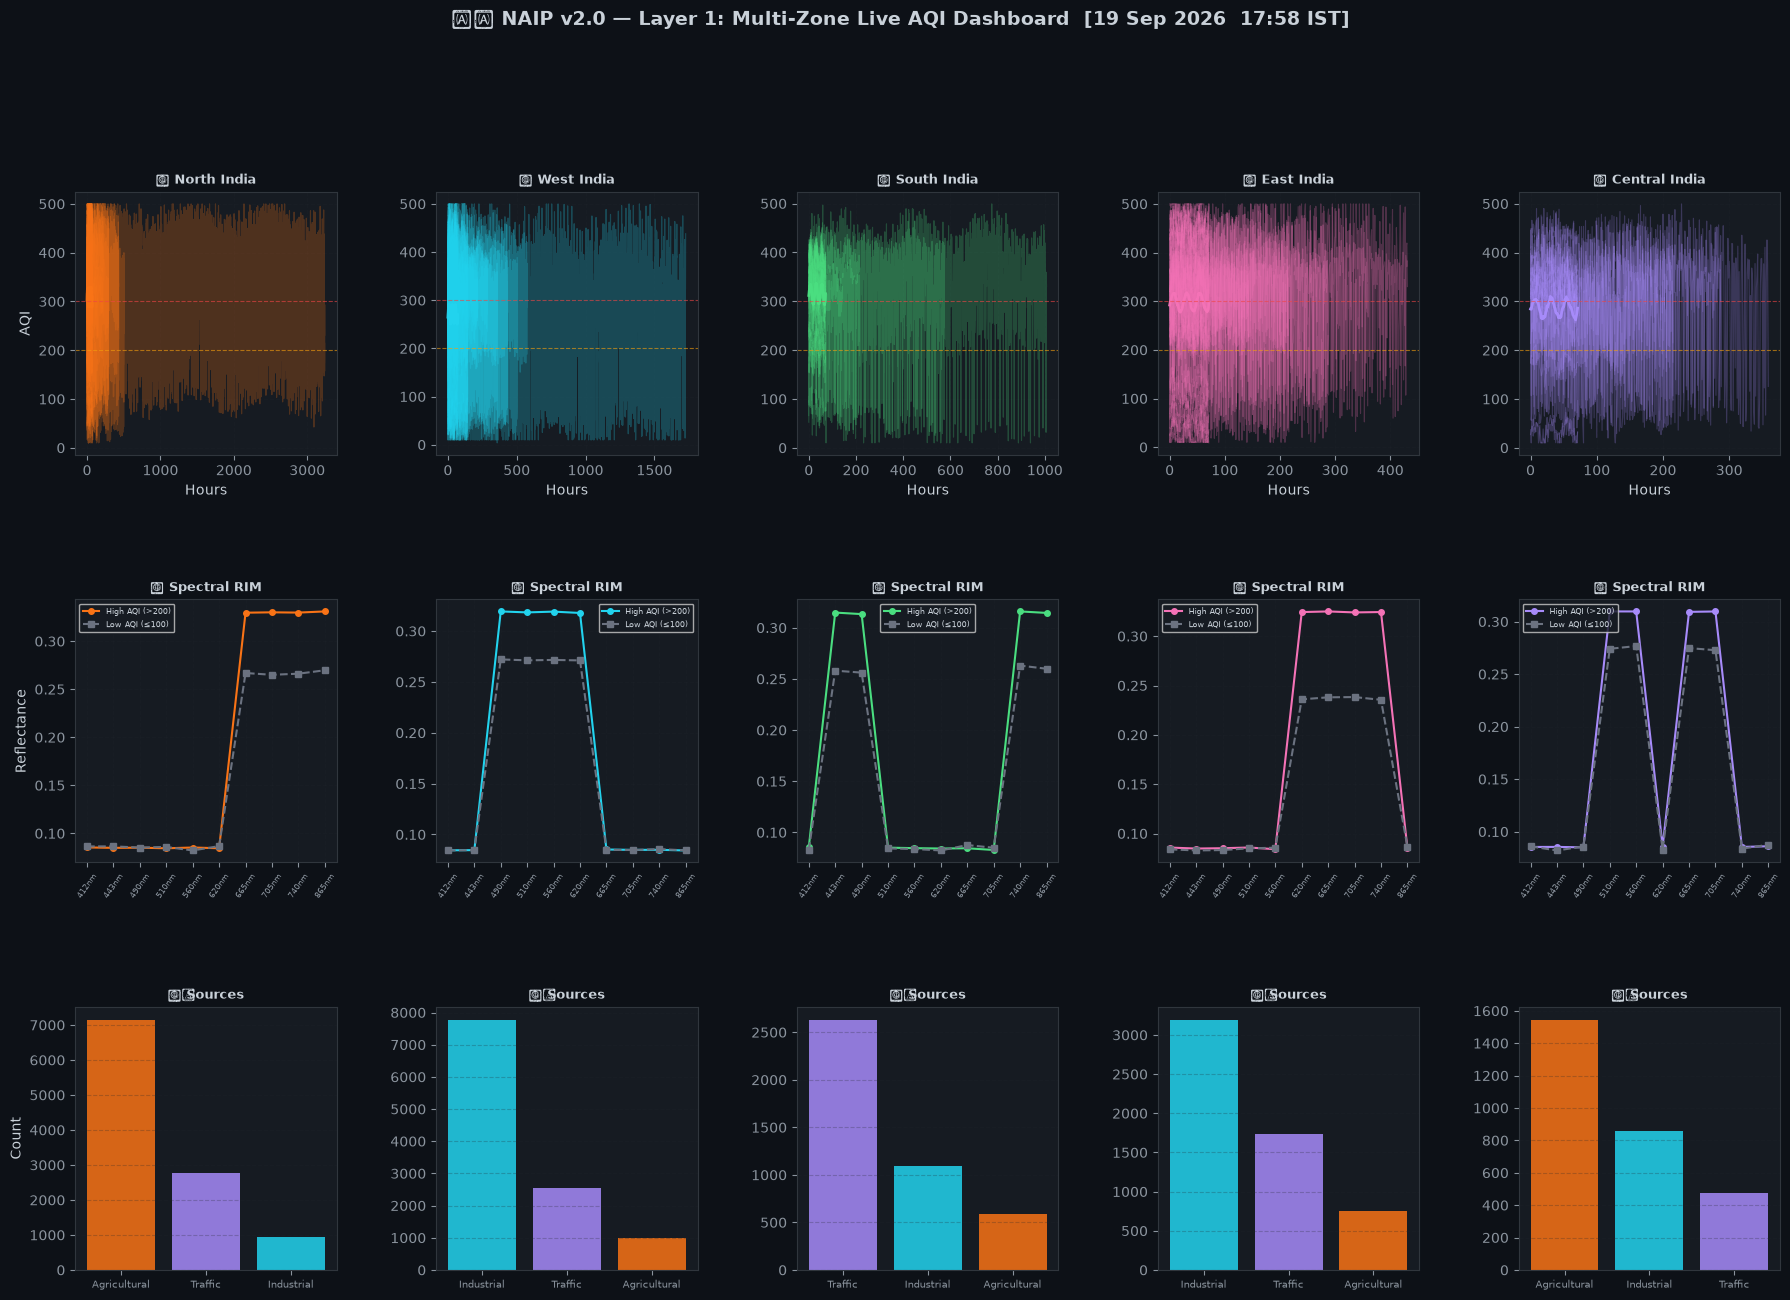

✅ Layer 1 multi-zone EDA complete.


In [7]:
# ─────────────────────────────────────────────────────────────────
#  LAYER 1 — MULTI-ZONE EDA DASHBOARD
# ─────────────────────────────────────────────────────────────────

def plot_multizone_eda(zone_dataframes: dict):
    n_zones = len(zone_dataframes)
    fig = plt.figure(figsize=(22, 14))
    gs  = gridspec.GridSpec(3, n_zones, figure=fig, hspace=0.55, wspace=0.38)

    BANDS = [c for c in df_all.columns if c.startswith("Spectral_")]
    band_labels = [f"{WAVELENGTHS_NM[i]}nm" for i in range(N_BANDS)]

    zone_keys = list(zone_dataframes.keys())

    # ── Row 0: AQI time series per zone ──────────────────────────
    for col_idx, zone_key in enumerate(zone_keys):
        zdf   = zone_dataframes[zone_key]
        zcfg  = ZONE_CONFIG[zone_key]
        ax    = fig.add_subplot(gs[0, col_idx])

        # Plot each city in lighter shade, zone mean in bold
        for city in zdf["City"].unique():
            cdf = zdf[zdf["City"] == city].sort_values("Timestamp")
            ax.plot(range(len(cdf)), cdf["Hourly_AQI"],
                    color=zcfg["color"], alpha=0.25, lw=0.8)

        zone_mean = zdf.groupby("Timestamp")["Hourly_AQI"].mean()
        ax.plot(range(len(zone_mean)), zone_mean.values,
                color=zcfg["color"], lw=2.0, label="Zone Mean")

        ax.axhline(300, color="#ef4444", ls="--", lw=0.8, alpha=0.6)
        ax.axhline(200, color="#f59e0b", ls="--", lw=0.8, alpha=0.6)
        ax.set_title(f"📡 {zcfg['zone_label']}", fontsize=9, fontweight="bold")
        ax.set_ylabel("AQI" if col_idx == 0 else "")
        ax.set_xlabel("Hours")
        ax.grid(True, alpha=0.25)

    # ── Row 1: Spectral fingerprints ──────────────────────────────
    for col_idx, zone_key in enumerate(zone_keys):
        zdf   = zone_dataframes[zone_key]
        zcfg  = ZONE_CONFIG[zone_key]
        ax    = fig.add_subplot(gs[1, col_idx])

        high = zdf[zdf["Hourly_AQI"] > 200]
        low  = zdf[zdf["Hourly_AQI"] <= 100]
        if len(high) > 0:
            ax.plot(range(10), high[BANDS].mean().values,
                    color=zcfg["color"], marker="o", ms=4, lw=1.5, label="High AQI (>200)")
        if len(low) > 0:
            ax.plot(range(10), low[BANDS].mean().values,
                    color="#6b7280", marker="s", ms=4, lw=1.5, ls="--", label="Low AQI (≤100)")
        ax.set_xticks(range(10))
        ax.set_xticklabels(band_labels, rotation=55, fontsize=6)
        ax.set_title("🔬 Spectral RIM", fontsize=9, fontweight="bold")
        ax.set_ylabel("Reflectance" if col_idx == 0 else "")
        ax.legend(fontsize=6)
        ax.grid(True, alpha=0.25)

    # ── Row 2: Source distribution ────────────────────────────────
    for col_idx, zone_key in enumerate(zone_keys):
        zdf  = zone_dataframes[zone_key]
        zcfg = ZONE_CONFIG[zone_key]
        ax   = fig.add_subplot(gs[2, col_idx])

        src = zdf["Dominant_Source"].value_counts()
        bar_colors = ["#f97316" if s == "Agricultural" else
                      "#22d3ee" if s == "Industrial" else "#a78bfa"
                      for s in src.index]
        ax.bar(src.index, src.values, color=bar_colors, alpha=0.85)
        ax.set_title("🏷️ Sources", fontsize=9, fontweight="bold")
        ax.set_ylabel("Count" if col_idx == 0 else "")
        ax.tick_params(axis="x", labelsize=7)
        ax.grid(True, alpha=0.25, axis="y")

    fig.suptitle(
        f"🇮🇳 NAIP v2.0 — Layer 1: Multi-Zone Live AQI Dashboard  "
        f"[{datetime.now(IST).strftime('%d %b %Y  %H:%M IST')}]",
        fontsize=14, fontweight="bold", y=1.01
    )
    plt.tight_layout()
    plt.show()
    print("✅ Layer 1 multi-zone EDA complete.")


plot_multizone_eda(zone_dataframes)

---
## 🟨 LAYER 2 — PROCESS
### Unified Multi-Output Neural Network (All Zones)

In [8]:
# ─────────────────────────────────────────────────────────────────
#  LAYER 2 — PREPROCESSING PIPELINE
# ─────────────────────────────────────────────────────────────────

class NAIPPreprocessor:
    SPECTRAL_COLS      = [c for c in df_all.columns if c.startswith("Spectral_")]
    FEATURE_COLS       = ["Region_ID", "Hourly_AQI", "Wind_Speed",
                          "Temp_Inversion_Layer"] + SPECTRAL_COLS
    REGRESSION_TARGETS = ["AQI_T+24", "AQI_T+48", "AQI_T+72"]
    CLASS_TARGET       = "Dominant_Source"

    def __init__(self):
        self.feat_scaler = StandardScaler()
        self.tgt_scaler  = StandardScaler()
        self.label_enc   = LabelEncoder()
        self.n_classes   = None
        self.class_names = None

    def fit_transform(self, df: pd.DataFrame):
        X       = self.feat_scaler.fit_transform(df[self.FEATURE_COLS].values)
        y_reg   = self.tgt_scaler.fit_transform(df[self.REGRESSION_TARGETS].values)
        y_cls_i = self.label_enc.fit_transform(df[self.CLASS_TARGET].values)
        self.class_names = list(self.label_enc.classes_)
        self.n_classes   = len(self.class_names)
        y_cls   = keras.utils.to_categorical(y_cls_i, self.n_classes)
        return X.astype(np.float32), y_reg.astype(np.float32), y_cls.astype(np.float32)

    def inverse_transform_reg(self, y_scaled: np.ndarray) -> np.ndarray:
        return self.tgt_scaler.inverse_transform(y_scaled)


preprocessor = NAIPPreprocessor()
X, y_reg, y_cls = preprocessor.fit_transform(df_all)

X_tv, X_test, yr_tv, yr_test, yc_tv, yc_test = train_test_split(
    X, y_reg, y_cls, test_size=0.15, random_state=SEED, shuffle=True)
X_train, X_val, yr_train, yr_val, yc_train, yc_val = train_test_split(
    X_tv, yr_tv, yc_tv, test_size=0.176, random_state=SEED)

print(f"✅ Feature matrix shape : {X.shape}")
print(f"   Train : {X_train.shape[0]:>6,} samples")
print(f"   Val   : {X_val.shape[0]:>6,} samples")
print(f"   Test  : {X_test.shape[0]:>6,} samples")
print(f"   Classes: {preprocessor.class_names}")

✅ Feature matrix shape : (35064, 14)
   Train : 24,558 samples
   Val   :  5,246 samples
   Test  :  5,260 samples
   Classes: ['Agricultural', 'Industrial', 'Traffic']


In [9]:
# ─────────────────────────────────────────────────────────────────
#  LAYER 2 — UNIFIED MULTI-HEAD NEURAL NETWORK
# ─────────────────────────────────────────────────────────────────

def build_naip_model(n_features: int, n_classes: int,
                     trunk_units=(256, 128, 64),
                     head_units=32, dropout_rate=0.30) -> Model:
    inputs = Input(shape=(n_features,), name="sensor_input")
    x = inputs
    for i, units in enumerate(trunk_units):
        x = layers.Dense(units, name=f"trunk_dense_{i+1}")(x)
        x = layers.BatchNormalization(name=f"trunk_bn_{i+1}")(x)
        x = layers.Activation("swish", name=f"trunk_act_{i+1}")(x)
        x = layers.Dropout(dropout_rate, name=f"trunk_drop_{i+1}")(x)
    shared_repr = x

    # Head A — AQI Forecast Regression
    h_reg  = layers.Dense(head_units, activation="swish", name="head_reg_dense")(shared_repr)
    h_reg  = layers.Dropout(0.15, name="head_reg_drop")(h_reg)
    aqi_out = layers.Dense(3, activation="linear", name="aqi_forecast")(h_reg)

    # Head B — Pollution Source Classification
    h_cls  = layers.Dense(head_units, activation="swish", name="head_cls_dense")(shared_repr)
    h_cls  = layers.Dropout(0.15, name="head_cls_drop")(h_cls)
    src_out = layers.Dense(n_classes, activation="softmax", name="source_class")(h_cls)

    return Model(inputs=inputs, outputs=[aqi_out, src_out], name="NAIP_Unified_v2")


model = build_naip_model(
    n_features=X_train.shape[1],
    n_classes=preprocessor.n_classes
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss={"aqi_forecast": "mse", "source_class": "categorical_crossentropy"},
    loss_weights={"aqi_forecast": 1.0, "source_class": 0.5},
    metrics={"aqi_forecast": ["mae"], "source_class": ["accuracy"]},
)

model.summary()

Model: "NAIP_Unified_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sensor_input        │ (None, 14)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ trunk_dense_1       │ (None, 256)       │      3,840 │ sensor_input[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ trunk_bn_1          │ (None, 256)       │      1,024 │ trunk_dense_1[0]… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ trunk_act_1         │ (None, 256)       │          0 │ trunk_bn_1[0][0]  │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ trunk_drop_1        │ (None, 256)       │          0 │ trunk_act_1[0][0] │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ trunk_dense_2       │ (None, 128)       │     32,896 │ trunk_drop_1[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ trunk_bn_2          │ (None, 128)       │        512 │ trunk_dense_2[0]… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ trunk_act_2         │ (None, 128)       │          0 │ trunk_bn_2[0][0]  │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ trunk_drop_2        │ (None, 128)       │          0 │ trunk_act_2[0][0] │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ trunk_dense_3       │ (None, 64)        │      8,256 │ trunk_drop_2[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ trunk_bn_3          │ (None, 64)        │        256 │ trunk_dense_3[0]… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ trunk_act_3         │ (None, 64)        │          0 │ trunk_bn_3[0][0]  │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ trunk_drop_3        │ (None, 64)        │          0 │ trunk_act_3[0][0] │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_reg_dense      │ (None, 32)        │      2,080 │ trunk_drop_3[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_cls_dense      │ (None, 32)        │      2,080 │ trunk_drop_3[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_reg_drop       │ (None, 32)        │          0 │ head_reg_dense[0… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_cls_drop       │ (None, 32)        │          0 │ head_cls_dense[0

 Total params: 51,142 (199.77 KB)

 Trainable params: 50,246 (196.27 KB)

 Non-trainable params: 896 (3.50 KB)

In [10]:
# ─────────────────────────────────────────────────────────────────
#  LAYER 2 — TRAINING
# ─────────────────────────────────────────────────────────────────

callbacks = [
    EarlyStopping(monitor="val_loss", patience=25,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                      patience=8, min_lr=1e-6, verbose=1),
]

print("🧠 Training NAIP v2.0 Multi-Output Network on real-time data...")
history = model.fit(
    X_train,
    {"aqi_forecast": yr_train, "source_class": yc_train},
    validation_data=(X_val, {"aqi_forecast": yr_val, "source_class": yc_val}),
    epochs=200,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)
print("✅ Training complete.")

🧠 Training NAIP v2.0 Multi-Output Network on real-time data...
Epoch 1/200
384/384 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - aqi_forecast_loss: 0.1993 - aqi_forecast_mae: 0.3280 - loss: 0.6816 - source_class_accuracy: 0.5736 - source_class_loss: 0.9646 - val_aqi_forecast_loss: 0.0301 - val_aqi_forecast_mae: 0.1328 - val_loss: 0.4739 - val_source_class_accuracy: 0.6212 - val_source_class_loss: 0.8882 - learning_rate: 0.0010
Epoch 2/200
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - aqi_forecast_loss: 0.0904 - aqi_forecast_mae: 0.2332 - loss: 0.5490 - source_class_accuracy: 0.6112 - source_class_loss: 0.9168 - val_aqi_forecast_loss: 0.0240 - val_aqi_forecast_mae: 0.1186 - val_loss: 0.4660 - val_source_class_accuracy: 0.6258 - val_source_class_loss: 0.8849 - learning_rate: 0.0010
Epoch 3/200
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - aqi_forecast_loss: 0.0745 - aqi_forecast_mae: 0.2125 - loss: 0.5271 - source_class_accuracy: 0.6156 - source_class_loss: 0.9050 - val_aqi_forecast_loss: 0.0227 - val_aq

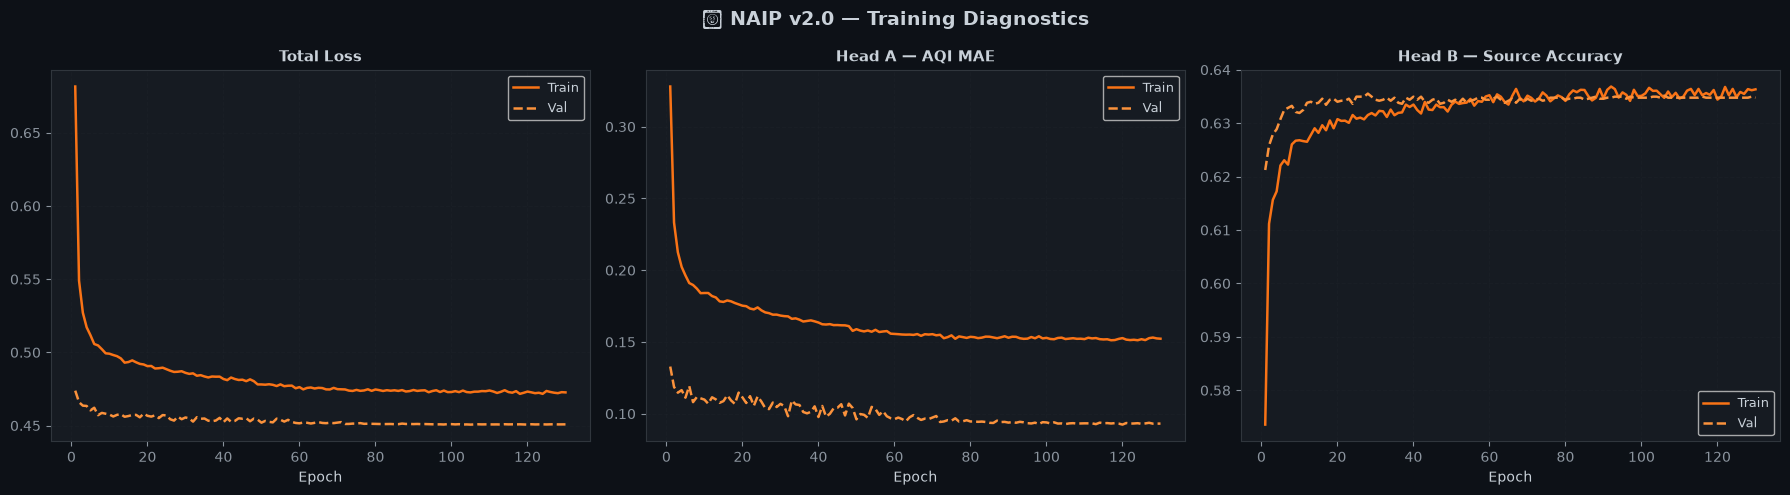


📊 Test-Set Evaluation
───────────────────────────────────────────────────────
  Head A (T+24h) — RMSE: 18.79  |  R²: 0.9780
  Head A (T+48h) — RMSE: 18.82  |  R²: 0.9777
  Head A (T+72h) — RMSE:  5.95  |  R²: 0.9978

  Head B Classification Report:
              precision    recall  f1-score   support

Agricultural     0.6111    0.7892    0.6889      1599
  Industrial     0.6523    0.7811    0.7109      2138
     Traffic     0.5890    0.2456    0.3466      1523

    accuracy                         0.6285      5260
   macro avg     0.6175    0.6053    0.5821      5260
weighted avg     0.6215    0.6285    0.5987      5260



In [11]:
# ─────────────────────────────────────────────────────────────────
#  LAYER 2 — EVALUATION
# ─────────────────────────────────────────────────────────────────

def plot_training_history(history):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    panels = [
        ("loss", "val_loss", "Total Loss"),
        ("aqi_forecast_mae", "val_aqi_forecast_mae", "Head A — AQI MAE"),
        ("source_class_accuracy", "val_source_class_accuracy", "Head B — Source Accuracy"),
    ]
    for ax, (tk, vk, title) in zip(axes, panels):
        ep = range(1, len(history.history[tk]) + 1)
        ax.plot(ep, history.history[tk],  color="#f97316", lw=1.8, label="Train")
        ax.plot(ep, history.history[vk],  color="#fb923c", lw=1.8, ls="--", label="Val")
        ax.set_title(title, fontsize=11, fontweight="bold")
        ax.set_xlabel("Epoch")
        ax.legend(fontsize=9)
        ax.grid(True, alpha=0.3)
    fig.suptitle("🧠 NAIP v2.0 — Training Diagnostics", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

plot_training_history(history)

pred_reg_scaled, pred_cls_prob = model.predict(X_test, verbose=0)
pred_reg = preprocessor.inverse_transform_reg(pred_reg_scaled)
true_reg = preprocessor.inverse_transform_reg(yr_test)

print("\n📊 Test-Set Evaluation")
print("─" * 55)
for i, horizon in enumerate(["T+24h", "T+48h", "T+72h"]):
    mse = mean_squared_error(true_reg[:, i], pred_reg[:, i])
    r2  = r2_score(true_reg[:, i], pred_reg[:, i])
    print(f"  Head A ({horizon}) — RMSE: {mse**0.5:5.2f}  |  R²: {r2:.4f}")

pred_cls = np.argmax(pred_cls_prob, axis=1)
true_cls = np.argmax(yc_test, axis=1)
print(f"\n  Head B Classification Report:")
print(classification_report(
    true_cls, pred_cls,
    target_names=preprocessor.class_names, digits=4
))

---
## 🟩 LAYER 3 — ACT
### Policy Command Center — All Zones

In [12]:
# ─────────────────────────────────────────────────────────────────
#  LAYER 3 — SURGICAL RECOMMENDATION ENGINE (All 5 Zones)
# ─────────────────────────────────────────────────────────────────

class SurgicalRecommendationEngine:
    PLAYBOOK = {
        ("North_Delhi",    "Agricultural"): (0.55, "🌾 Activate crop-residue burning ban. Alert Punjab & Haryana PPCB. Deploy drone surveillance over stubble fields.", "Central CPCB + State PPCB", "#ef4444"),
        ("North_Delhi",    "Traffic"):      (0.50, "🚗 Enforce odd-even vehicular restriction in NCR. Expand CNG mandate; suspend high-polluting diesel fleets.", "Delhi Transport Authority", "#f59e0b"),
        ("North_Delhi",    "Industrial"):   (0.45, "🏭 Issue 48-hr stack emission compliance notice to NCR industries. Halt brick kilns and coal-based units.", "DPCC + MoEFCC", "#f97316"),
        ("West_Vadodara",  "Industrial"):   (0.55, "⚗️  Enforce SO₂/VOC caps in Vadodara GIDC cluster. CEMS reporting within 24 hrs. GPCB inspection.", "GPCB + MoEFCC", "#ef4444"),
        ("West_Vadodara",  "Traffic"):      (0.50, "🚗 Restrict HGV movement on NH48 (06:00–22:00). Activate green zone buffers near residential areas.", "Vadodara Municipal Corp", "#f59e0b"),
        ("West_Vadodara",  "Agricultural"): (0.45, "🌾 Issue advisory to restrict field burning in South Gujarat. Engage ATMA agricultural extension officers.", "Gujarat State PPCB", "#22d3ee"),
        ("South_Bangalore","Traffic"):      (0.55, "🚗 Expand metro/bus rapid transit capacity. Odd-even enforcement on Outer Ring Road and MG Road.", "BBMP + Karnataka SPCB", "#f59e0b"),
        ("South_Bangalore","Industrial"):   (0.50, "🏭 Inspection of Peenya & Whitefield industrial zones. Enforce emission norms for IT park diesel generators.", "KSPCB + MoEFCC", "#f97316"),
        ("South_Bangalore","Agricultural"): (0.45, "🌾 Advisory on paddy/sugarcane burning in Mandya and Hassan districts.", "Karnataka SPCB", "#4ade80"),
        ("East_Kolkata",   "Industrial"):   (0.55, "🏭 Halt coal-fired units at Durgapur and Asansol. Issue STO to Haldia petrochemical cluster.", "WBPCB + MoEFCC", "#ef4444"),
        ("East_Kolkata",   "Traffic"):      (0.50, "🚗 Strengthen vehicle fitness inspection drive in Kolkata metro. Expand e-bus corridor.", "Kolkata Traffic Police", "#f59e0b"),
        ("East_Kolkata",   "Agricultural"): (0.45, "🌾 Advisory on jute/paddy burning in 24 Parganas and Murshidabad.", "WBPCB", "#f472b6"),
        ("Central_Bhopal", "Agricultural"): (0.50, "🌾 Activate stubble-burning ban in Madhya Pradesh. Alert district collectors in soybean belt.", "MP PPCB + Agriculture Dept", "#ef4444"),
        ("Central_Bhopal", "Industrial"):   (0.50, "🏭 Inspect cement/steel plants in Jabalpur and Satna. Issue show-cause to non-compliant units.", "MP PPCB + MoEFCC", "#f97316"),
        ("Central_Bhopal", "Traffic"):      (0.45, "🚗 Fleet modernisation advisory for state buses. Strengthen PUC enforcement in Bhopal and Indore.", "MP Transport Authority", "#a78bfa"),
    }
    DEFAULT_ACTION = ("⚠️ Mixed pollution episode. Activate GRAP Stage II protocols. Increase monitoring frequency to 30-min intervals.", "Central CPCB", "#8b949e")

    def recommend(self, region: str, source_probs: np.ndarray, class_names: list) -> dict:
        top_idx    = np.argmax(source_probs)
        top_src    = class_names[top_idx]
        confidence = float(source_probs[top_idx])
        key   = (region, top_src)
        entry = self.PLAYBOOK.get(key)
        if entry and confidence >= entry[0]:
            action, authority, color = entry[1], entry[2], entry[3]
        else:
            action, authority, color = self.DEFAULT_ACTION
        return {
            "region":     region,
            "source":     top_src,
            "confidence": confidence,
            "probs":      {class_names[i]: float(source_probs[i]) for i in range(len(class_names))},
            "action":     action,
            "authority":  authority,
            "color":      color,
        }


rec_engine = SurgicalRecommendationEngine()
print("✅ Surgical Recommendation Engine initialised (5 zones, 15 playbook entries).")

✅ Surgical Recommendation Engine initialised (5 zones, 15 playbook entries).


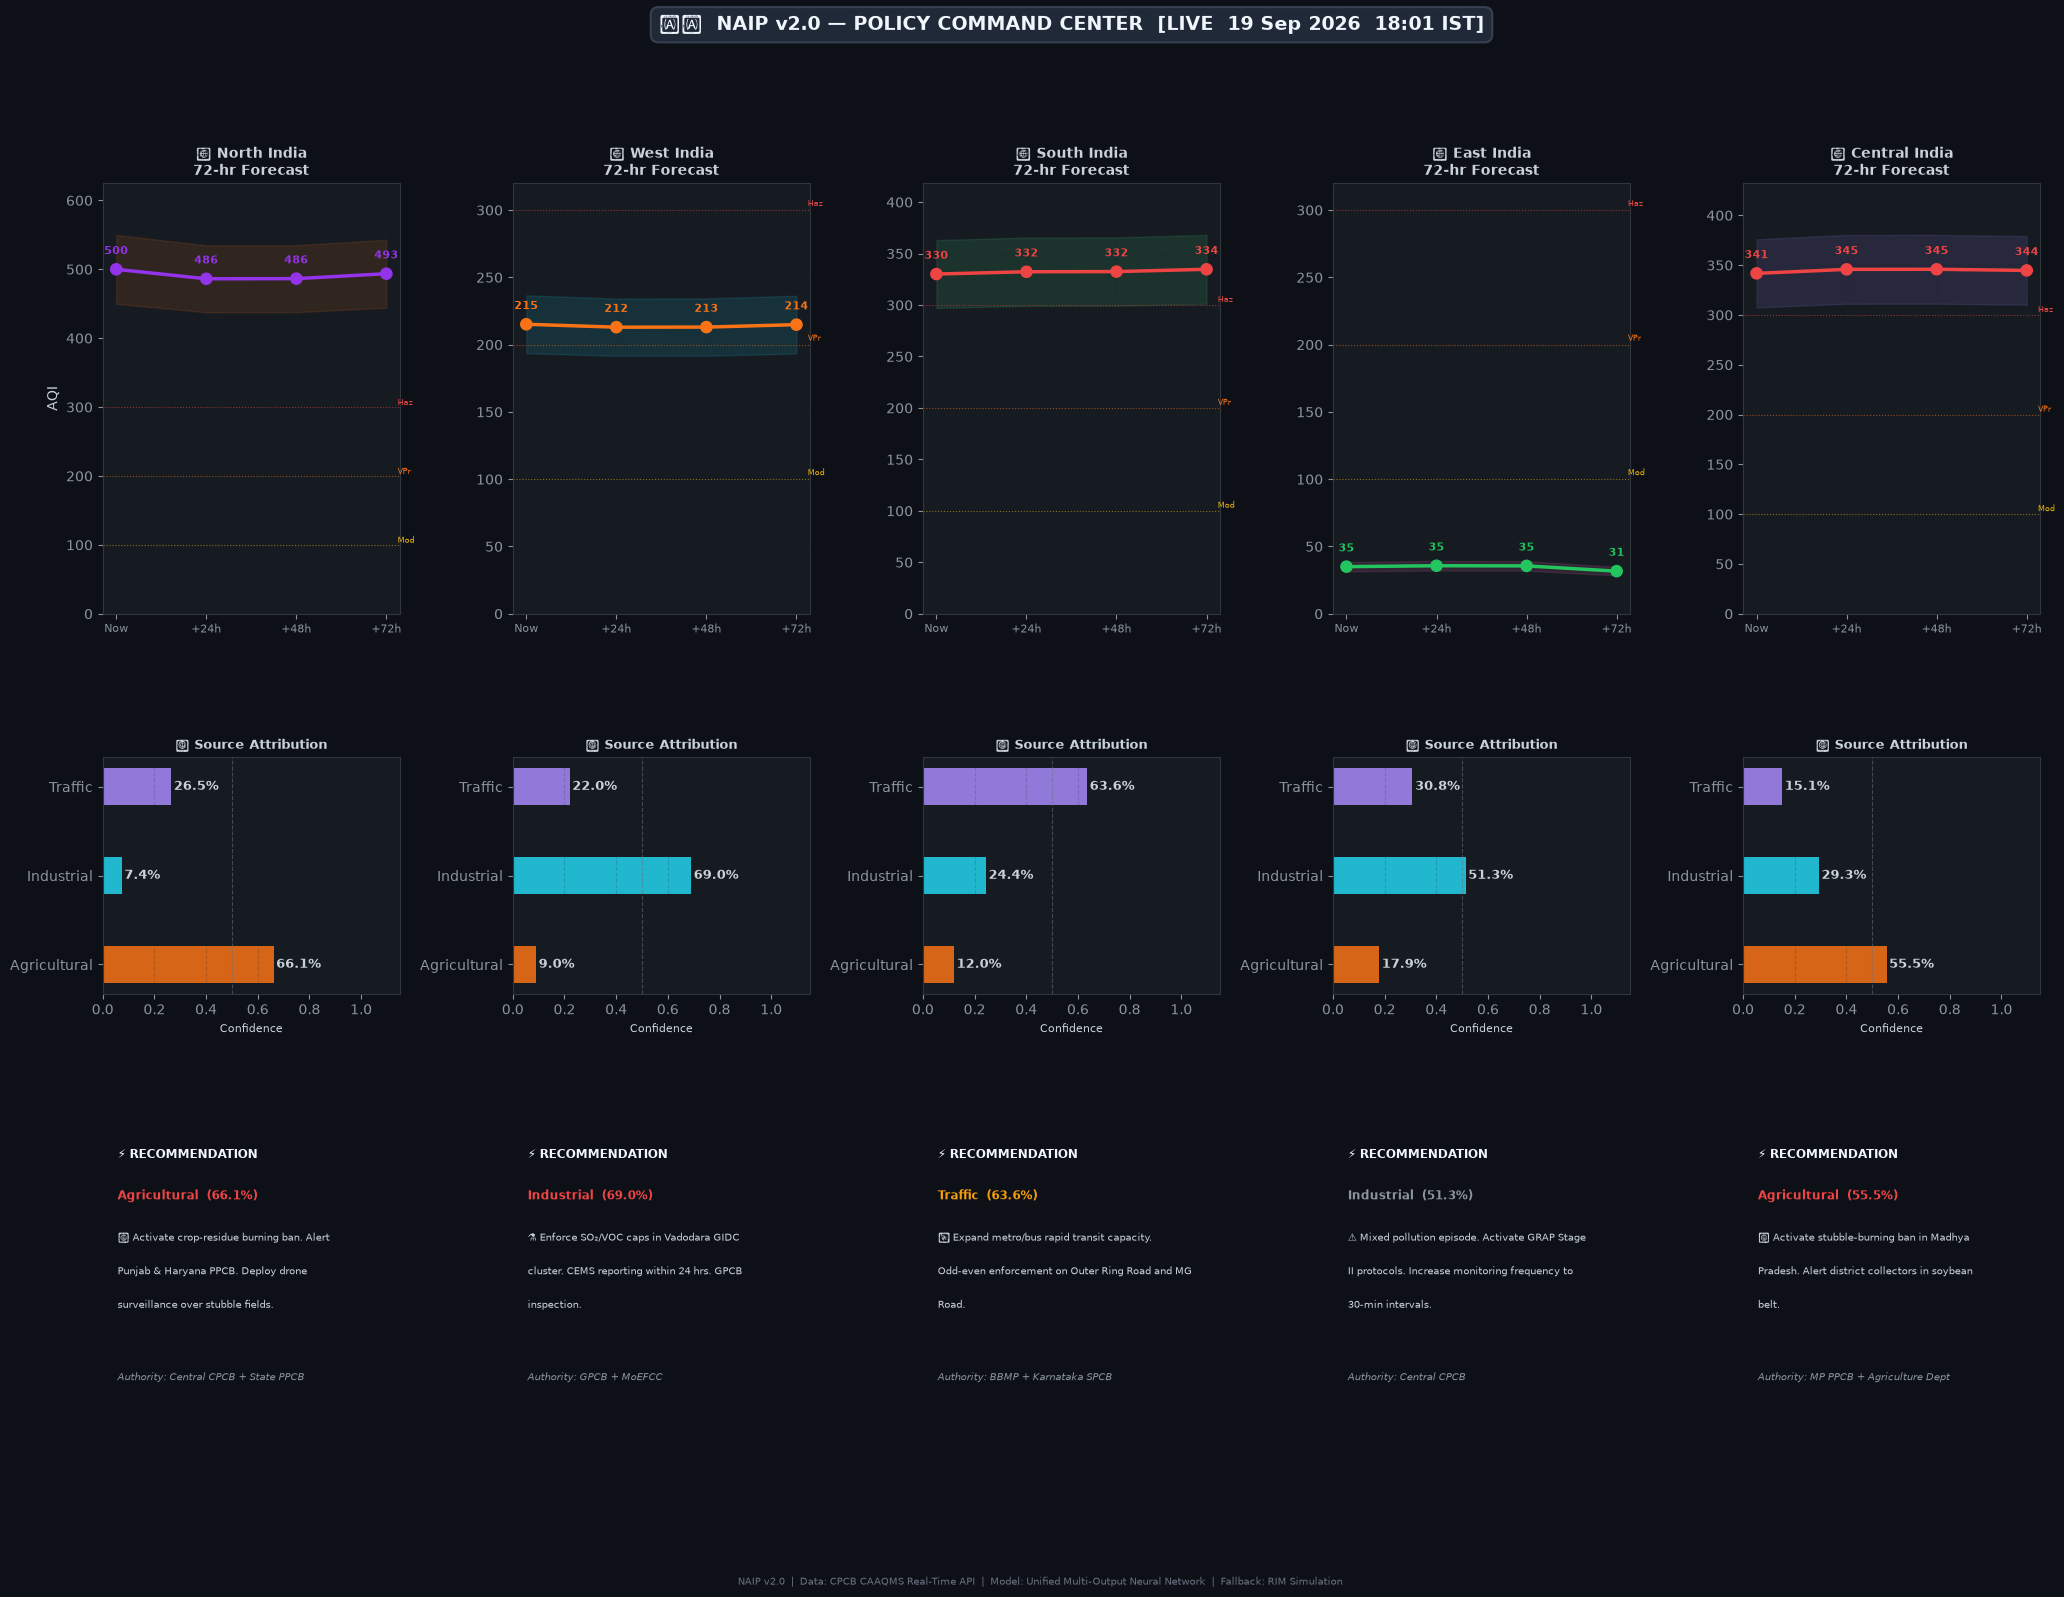


📋 LIVE RECOMMENDATIONS SUMMARY
══════════════════════════════════════════════════════════════════════
  [North India]
   Current AQI : 500
   Forecast    : +24h=486  +48h=486  +72h=494
   Source      : Agricultural (66.1% confidence)
   Action      : 🌾 Activate crop-residue burning ban. Alert Punjab & Haryana PPCB. Deploy dr...
   Authority   : Central CPCB + State PPCB

  [West India]
   Current AQI : 215
   Forecast    : +24h=213  +48h=213  +72h=215
   Source      : Industrial (69.0% confidence)
   Action      : ⚗️  Enforce SO₂/VOC caps in Vadodara GIDC cluster. CEMS reporting within 24...
   Authority   : GPCB + MoEFCC

  [South India]
   Current AQI : 330
   Forecast    : +24h=332  +48h=333  +72h=335
   Source      : Traffic (63.6% confidence)
   Action      : 🚗 Expand metro/bus rapid transit capacity. Odd-even enforcement on Outer Ri...
   Authority   : BBMP + Karnataka SPCB

  [East India]
   Current AQI : 35
   Forecast    : +24h=36  +48h=36  +72h=32
   Source      : Industrial

In [13]:
# ─────────────────────────────────────────────────────────────────
#  LAYER 3 — POLICY COMMAND CENTER DASHBOARD
# ─────────────────────────────────────────────────────────────────

def policy_command_center_v2(model, preprocessor, rec_engine, zone_dataframes):
    FEATURE_COLS = preprocessor.FEATURE_COLS
    n_zones = len(zone_dataframes)

    def aqi_color(v):
        if v <= 50:  return "#22c55e"
        if v <= 100: return "#84cc16"
        if v <= 200: return "#eab308"
        if v <= 300: return "#f97316"
        if v <= 400: return "#ef4444"
        return "#9333ea"

    def zone_inference(zdf, zone_key):
        row     = zdf.iloc[-1][FEATURE_COLS].values.reshape(1, -1)
        X_in    = preprocessor.feat_scaler.transform(row).astype(np.float32)
        p_reg, p_cls = model.predict(X_in, verbose=0)
        forecast = preprocessor.inverse_transform_reg(p_reg)[0]
        rec      = rec_engine.recommend(zone_key, p_cls[0], preprocessor.class_names)
        return forecast, rec, float(zdf.iloc[-1]["Hourly_AQI"])

    zone_results = {}
    for zone_key, zdf in zone_dataframes.items():
        zone_results[zone_key] = zone_inference(zdf, zone_key)

    # ── Layout: n_zones columns ───────────────────────────────────
    fig = plt.figure(figsize=(5 * n_zones, 18))
    gs  = gridspec.GridSpec(4, n_zones, figure=fig, hspace=0.60, wspace=0.38,
                             height_ratios=[0.07, 1.0, 0.55, 0.60])

    # ── Title ─────────────────────────────────────────────────────
    ax_t = fig.add_subplot(gs[0, :])
    ax_t.axis("off")
    ax_t.text(
        0.5, 0.5,
        f"🇮🇳  NAIP v2.0 — POLICY COMMAND CENTER  "
        f"[LIVE  {datetime.now(IST).strftime('%d %b %Y  %H:%M IST')}]",
        ha="center", va="center", fontsize=14, fontweight="bold", color="#f0f6fc",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="#1f2937",
                  edgecolor="#374151", linewidth=1.5)
    )

    horizons    = ["Now", "+24h", "+48h", "+72h"]
    x_positions = [0, 24, 48, 72]

    for col_idx, zone_key in enumerate(zone_dataframes):
        zcfg         = ZONE_CONFIG[zone_key]
        forecast, rec, current_aqi = zone_results[zone_key]
        aqi_series   = np.array([current_aqi] + list(forecast))
        seg_colors   = [aqi_color(v) for v in aqi_series]

        # ── Forecast ribbon ───────────────────────────────────────
        ax_f = fig.add_subplot(gs[1, col_idx])
        for i in range(len(x_positions) - 1):
            ax_f.plot(x_positions[i:i+2], aqi_series[i:i+2],
                      color=seg_colors[i], lw=2.5, solid_capstyle="round")
        ax_f.scatter(x_positions, aqi_series, color=seg_colors, s=65, zorder=5)
        ax_f.fill_between(x_positions,
                           aqi_series * 0.90, aqi_series * 1.10,
                           alpha=0.12, color=zcfg["color"])
        for tval, tcol, tlbl in [(300, "#ef4444", "Haz"), (200, "#f97316", "VPr"), (100, "#eab308", "Mod")]:
            ax_f.axhline(tval, color=tcol, ls=":", lw=0.8, alpha=0.55)
            ax_f.text(75, tval + 3, tlbl, fontsize=6, color=tcol)
        for xp, yp, lbl in zip(x_positions, aqi_series, horizons):
            ax_f.annotate(f"{int(yp)}", xy=(xp, yp), xytext=(0, 11),
                           textcoords="offset points", ha="center",
                           fontsize=8, fontweight="bold", color=aqi_color(yp))
        ax_f.set_xticks(x_positions)
        ax_f.set_xticklabels(horizons, fontsize=8)
        ax_f.set_ylabel("AQI" if col_idx == 0 else "")
        ax_f.set_ylim(0, max(aqi_series.max() * 1.25, 320))
        ax_f.set_title(f"📍 {zcfg['zone_label']}\n72-hr Forecast",
                        fontsize=10, fontweight="bold", pad=6)
        ax_f.grid(True, alpha=0.22)

        # ── Source attribution gauge ───────────────────────────────
        ax_g = fig.add_subplot(gs[2, col_idx])
        probs  = rec["probs"]
        labels = list(probs.keys())
        values = list(probs.values())
        bar_colors = ["#f97316" if l == "Agricultural" else
                      "#22d3ee" if l == "Industrial" else "#a78bfa"
                      for l in labels]
        bars = ax_g.barh(labels, values, color=bar_colors, height=0.42, alpha=0.85)
        for bar, val in zip(bars, values):
            ax_g.text(val + 0.01, bar.get_y() + bar.get_height() / 2,
                       f"{val:.1%}", va="center", fontsize=9, fontweight="bold")
        ax_g.set_xlim(0, 1.15)
        ax_g.set_xlabel("Confidence", fontsize=8)
        ax_g.set_title("🔎 Source Attribution", fontsize=9, fontweight="bold")
        ax_g.axvline(0.5, color="#6b7280", ls="--", lw=0.8, alpha=0.55)
        ax_g.grid(True, alpha=0.18, axis="x")

        # ── Recommendation panel ──────────────────────────────────
        ax_r = fig.add_subplot(gs[3, col_idx])
        ax_r.axis("off")
        ax_r.text(0.05, 0.92, "⚡ RECOMMENDATION",
                   transform=ax_r.transAxes, fontsize=8.5, fontweight="bold", color="#f0f6fc")
        ax_r.text(0.05, 0.76,
                   f"{rec['source']}  ({rec['confidence']:.1%})",
                   transform=ax_r.transAxes, fontsize=8.5, color=rec["color"], fontweight="bold")

        words = rec["action"].split()
        lines, line = [], ""
        for w in words:
            if len(line) + len(w) + 1 < 48:
                line += (" " if line else "") + w
            else:
                lines.append(line); line = w
        if line: lines.append(line)
        for j, al in enumerate(lines[:5]):
            ax_r.text(0.05, 0.60 - j * 0.13, al,
                       transform=ax_r.transAxes, fontsize=7.5, color="#c9d1d9")
        ax_r.text(0.05, 0.06, f"Authority: {rec['authority']}",
                   transform=ax_r.transAxes, fontsize=7, color="#8b949e", style="italic")
        for sp in ax_r.spines.values():
            sp.set_visible(True); sp.set_color(rec["color"]); sp.set_linewidth(1.5)

    fig.text(0.5, 0.005,
             "NAIP v2.0  |  Data: CPCB CAAQMS Real-Time API  |  "
             "Model: Unified Multi-Output Neural Network  |  Fallback: RIM Simulation",
             ha="center", fontsize=7, color="#6b7280")
    plt.show()

    # ── Text Summary ──────────────────────────────────────────────
    print("\n📋 LIVE RECOMMENDATIONS SUMMARY")
    print("═" * 70)
    for zone_key in zone_dataframes:
        fc, rec, aqi_now = zone_results[zone_key]
        print(f"  [{ZONE_CONFIG[zone_key]['zone_label']}]")
        print(f"   Current AQI : {aqi_now:.0f}")
        print(f"   Forecast    : +24h={fc[0]:.0f}  +48h={fc[1]:.0f}  +72h={fc[2]:.0f}")
        print(f"   Source      : {rec['source']} ({rec['confidence']:.1%} confidence)")
        print(f"   Action      : {rec['action'][:75]}...")
        print(f"   Authority   : {rec['authority']}")
        print()


policy_command_center_v2(
    model=model,
    preprocessor=preprocessor,
    rec_engine=rec_engine,
    zone_dataframes=zone_dataframes,
)

---
## 📦 LAYER 3 — Model Export + Live Inference API

In [14]:
# ─────────────────────────────────────────────────────────────────
#  LAYER 3 — MODEL EXPORT
# ─────────────────────────────────────────────────────────────────

model.save("naip_model_v2.keras")
print("✅ Model saved → naip_model_v2.keras")

# The Streamlit app needs the fitted scalers and label encoder as well.
import pickle
with open("naip_preprocessor_v2.pkl", "wb") as f:
    pickle.dump(preprocessor, f)
print("✅ Preprocessor saved → naip_preprocessor_v2.pkl")

converter  = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_mdl = converter.convert()
with open("naip_model_v2_edge.tflite", "wb") as f:
    f.write(tflite_mdl)
print(f"✅ TFLite edge model saved ({len(tflite_mdl)/1024:.1f} KB)")

✅ Model saved → naip_model_v2.keras
✅ Preprocessor saved → naip_preprocessor_v2.pkl
INFO:tensorflow:Assets written to: C:\Users\Sahil\AppData\Local\Temp\tmp_ab5ofbz\assets


INFO:tensorflow:Assets written to: C:\Users\Sahil\AppData\Local\Temp\tmp_ab5ofbz\assets


Saved artifact at 'C:\Users\Sahil\AppData\Local\Temp\tmp_ab5ofbz'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 14), dtype=tf.float32, name='sensor_input')
Output Type:
  List[TensorSpec(shape=(None, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)]
Captures:
  2140403918432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2140328539584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2140404080928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2140404082128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2140326240336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2140404081168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2140404083088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2140404081888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2140404084288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2140404083568: Ten

In [15]:
# ─────────────────────────────────────────────────────────────────
#  LAYER 3 — LIVE INFERENCE API
# ─────────────────────────────────────────────────────────────────

def naip_infer_live(region: str, city: str = None) -> dict:
    """
    Live inference: Fetches current AQI for a zone from data.gov.in,
    derives RIM features, and returns 72-hr forecast + recommendation.

    Parameters
    ----------
    region : Zone key (e.g. 'North_Delhi')
    city   : Optional — filter to a specific city name within the zone
    """
    assert region in ZONE_CONFIG, f"Unknown region: {region}"
    zone_cfg = ZONE_CONFIG[region]

    live_df = fetcher._fetch_state_live(zone_cfg["states"])
    if live_df is not None and not live_df.empty:
        if city:
            city_df = live_df[live_df["city"].str.contains(city, case=False, na=False)]
            if not city_df.empty:
                live_df = city_df
        # Compute zone-level mean live AQI
        aqis = []
        for (c, s), sdf in live_df.groupby(["city","station"]):
            aqi = fetcher._station_aqi(sdf)
            if aqi: aqis.append(aqi)
        live_aqi = float(np.mean(aqis)) if aqis else float(zone_cfg.get("base_aqi", 160))
        data_src = "CPCB_Live"
    else:
        live_aqi = float(zone_cfg.get("base_aqi", 160))
        data_src = "RIM_Fallback"

    feat = fetcher._derive_features(np.array([live_aqi], dtype=np.float32), zone_cfg)
    spectral_vals = [float(feat["spectral"][0, i]) for i in range(N_BANDS)]

    result = naip_infer(
        region         = region,
        hourly_aqi     = live_aqi,
        wind_speed     = float(feat["wind"][0]),
        temp_inversion = float(feat["inv"][0]),
        spectral_array = spectral_vals
    )
    result["data_source"] = data_src
    return result


def naip_infer(region: str, hourly_aqi: float, wind_speed: float,
               temp_inversion: float, spectral_array: list) -> dict:
    """Manual inference (for testing or edge deployment)."""
    assert len(spectral_array) == 10
    region_ids = {k: ZONE_CONFIG[k]["region_id"] for k in ZONE_CONFIG}
    feat = np.array([[region_ids[region], hourly_aqi, wind_speed,
                       temp_inversion] + spectral_array], dtype=np.float32)
    X_in = preprocessor.feat_scaler.transform(feat).astype(np.float32)
    p_reg, p_cls = model.predict(X_in, verbose=0)
    forecast = preprocessor.inverse_transform_reg(p_reg)[0]
    rec      = rec_engine.recommend(region, p_cls[0], preprocessor.class_names)
    return {
        "region":             region,
        "zone_label":         ZONE_CONFIG[region]["zone_label"],
        "timestamp_ist":      datetime.now(IST).strftime("%Y-%m-%d %H:%M IST"),
        "current_aqi":        hourly_aqi,
        "forecast": {
            "T+24h": round(float(forecast[0]), 1),
            "T+48h": round(float(forecast[1]), 1),
            "T+72h": round(float(forecast[2]), 1),
        },
        "source_attribution": {k: round(v, 4) for k, v in rec["probs"].items()},
        "dominant_source":    rec["source"],
        "confidence":         round(rec["confidence"], 4),
        "recommendation":     rec["action"],
        "issuing_authority":  rec["authority"],
    }


# ── Live inference demo calls ─────────────────────────────────────
print("📡 NAIP v2.0 — Live Inference API Demo")
print("═" * 65)

live_test_zones = [
    ("North_Delhi",     "Delhi"),
    ("West_Vadodara",   "Vadodara"),
    ("South_Bangalore", "Bangalore"),
    ("East_Kolkata",    "Kolkata"),
    ("Central_Bhopal",  "Bhopal"),
]

for region, city_hint in live_test_zones:
    print(f"\n🔍 Live inference for {region} (city hint: {city_hint})...")
    result = naip_infer_live(region, city=city_hint)
    print(f"   Zone        : {result['zone_label']}")
    print(f"   Timestamp   : {result['timestamp_ist']}")
    print(f"   Data Source : {result.get('data_source','?')}")
    print(f"   Current AQI : {result['current_aqi']:.0f}")
    print(f"   Forecast    : +24h={result['forecast']['T+24h']}  "
          f"+48h={result['forecast']['T+48h']}  +72h={result['forecast']['T+72h']}")
    print(f"   Dominant    : {result['dominant_source']} ({result['confidence']:.1%})")
    print(f"   Action      : {result['recommendation'][:75]}...")
    print(f"   Authority   : {result['issuing_authority']}")
    print("   " + "─" * 60)


📡 NAIP v2.0 — Live Inference API Demo
═════════════════════════════════════════════════════════════════

🔍 Live inference for North_Delhi (city hint: Delhi)...
   ✅ Delhi: 315 raw records fetched
   ✅ Haryana: 203 raw records fetched
   ✅ Uttar Pradesh: 462 raw records fetched
   ✅ Chandigarh: 21 raw records fetched
   ✅ Punjab: 56 raw records fetched
   Zone        : North India
   Timestamp   : 2026-09-19 18:01 IST
   Data Source : CPCB_Live
   Current AQI : 318
   Forecast    : +24h=338.7  +48h=338.7  +72h=329.5
   Dominant    : Agricultural (68.2%)
   Action      : 🌾 Activate crop-residue burning ban. Alert Punjab & Haryana PPCB. Deploy dr...
   Authority   : Central CPCB + State PPCB
   ────────────────────────────────────────────────────────────

🔍 Live inference for West_Vadodara (city hint: Vadodara)...
   ✅ Gujarat: 147 raw records fetched
   ✅ Maharashtra: 500 raw records fetched
   ✅ Rajasthan: 336 raw records fetched
   ⚠️  Goa: No records returned from API
   Zone        :

---
## ♻️ Optional — Refresh Live Data

Run this cell at any time to **re-fetch latest AQI from CPCB** and re-render the Command Center without retraining.

♻️  Refreshing live data at 18:01 IST...

━━━ North India ━━━
   Fetching states: Delhi, Haryana, Uttar Pradesh, Chandigarh, Punjab
   ✅ Delhi: 315 raw records fetched
   ✅ Haryana: 203 raw records fetched
   ✅ Uttar Pradesh: 462 raw records fetched
   ✅ Chandigarh: 21 raw records fetched
   ✅ Punjab: 56 raw records fetched
   📍 Built 151 stations × 72h = 10,872 records
   📊 North India: 10,872 records | {'CPCB_Live': 10872}

━━━ West India ━━━
   Fetching states: Gujarat, Maharashtra, Rajasthan, Goa
   ✅ Gujarat: 147 raw records fetched
   ✅ Maharashtra: 500 raw records fetched
   ✅ Rajasthan: 336 raw records fetched
   ⚠️  Goa: No records returned from API
   📍 Built 157 stations × 72h = 11,304 records
   📊 West India: 11,304 records | {'CPCB_Live': 11304}

━━━ South India ━━━
   Fetching states: Karnataka, Tamil Nadu, Telangana, Andhra Pradesh, Kerala
   ✅ Karnataka: 154 raw records fetched
   ✅ Tamil Nadu: 28 raw records fetched
   ✅ Telangana: 98 raw records fetched
   ✅ Andhra Pr

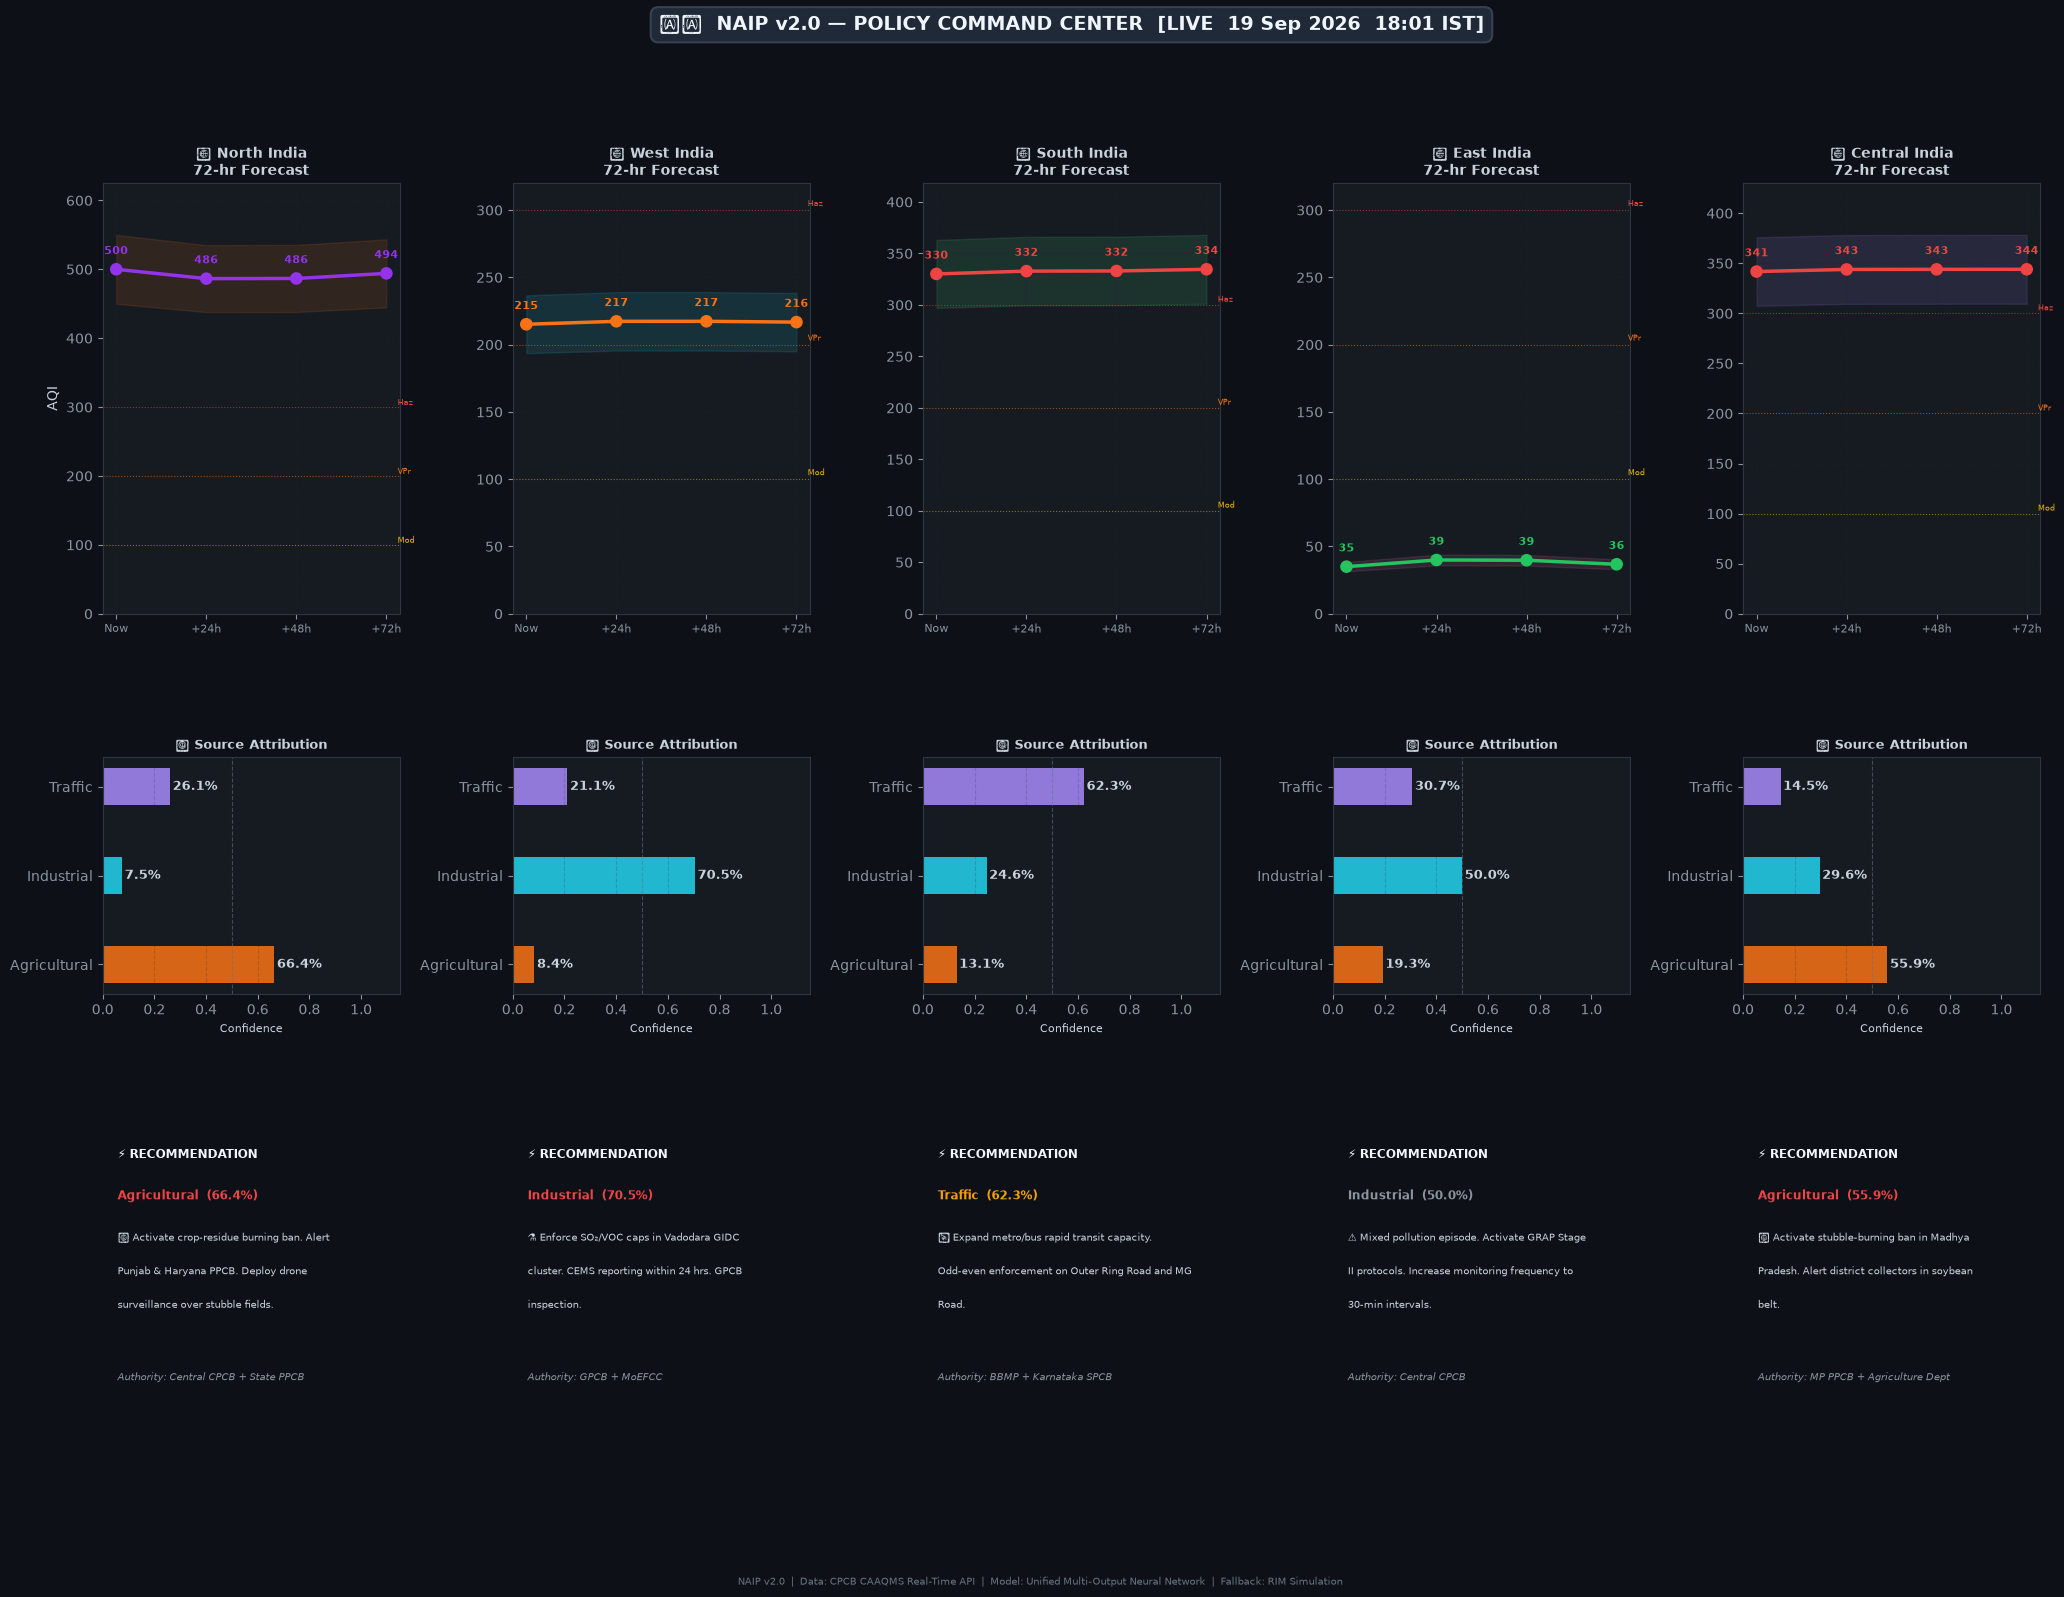


📋 LIVE RECOMMENDATIONS SUMMARY
══════════════════════════════════════════════════════════════════════
  [North India]
   Current AQI : 500
   Forecast    : +24h=486  +48h=487  +72h=494
   Source      : Agricultural (66.4% confidence)
   Action      : 🌾 Activate crop-residue burning ban. Alert Punjab & Haryana PPCB. Deploy dr...
   Authority   : Central CPCB + State PPCB

  [West India]
   Current AQI : 215
   Forecast    : +24h=217  +48h=217  +72h=217
   Source      : Industrial (70.5% confidence)
   Action      : ⚗️  Enforce SO₂/VOC caps in Vadodara GIDC cluster. CEMS reporting within 24...
   Authority   : GPCB + MoEFCC

  [South India]
   Current AQI : 330
   Forecast    : +24h=333  +48h=333  +72h=335
   Source      : Traffic (62.3% confidence)
   Action      : 🚗 Expand metro/bus rapid transit capacity. Odd-even enforcement on Outer Ri...
   Authority   : BBMP + Karnataka SPCB

  [East India]
   Current AQI : 35
   Forecast    : +24h=40  +48h=40  +72h=37
   Source      : Industrial

In [16]:
# ─────────────────────────────────────────────────────────────────
#  ♻️  REFRESH — Re-fetch live data + re-run inference only
#  (No retraining needed — uses already-trained model)
# ─────────────────────────────────────────────────────────────────

print(f"♻️  Refreshing live data at {datetime.now(IST).strftime('%H:%M IST')}...")

zone_dataframes_live = {}
for zone_key in ZONE_CONFIG:
    print(f"\n━━━ {ZONE_CONFIG[zone_key]['zone_label']} ━━━")
    zone_dataframes_live[zone_key] = fetcher.fetch_zone(zone_key)

print("\n✅ Data refreshed. Re-rendering Command Center...\n")

policy_command_center_v2(
    model=model,
    preprocessor=preprocessor,
    rec_engine=rec_engine,
    zone_dataframes=zone_dataframes_live,
)


## 📋 Version Change Log

| Feature | v1.0 PoC | v2.0 Real-Time | v2.1 API Fix |
|---------|----------|----------------|---------------|
| API Host | `api.cpcbccr.com` (wrong) | `api.cpcbccr.com` (wrong) | **`api.data.gov.in` (correct)** |
| Auth method | Bearer token | Bearer token | **`?api-key=` query param** |
| Resource ID | — | Used as API key (wrong) | **Used as URL path segment (correct)** |
| Station filtering | By station_id | By station_id | **By state name** |
| AQI computation | Direct from API | Direct from API | **NAQI 2014 sub-index from pollutant avg** |
| Temporal data | 72-hr hourly fetch | 72-hr hourly fetch | **Live anchor + RIM diurnal simulation** |
| API fallback | Per-station RIM | Per-station RIM | **Per-zone RIM with realistic cities** |

---
*NAIP v2.1 — API-Fixed Edition | Data: CPCB via data.gov.in | Framework: TensorFlow/Keras*
